# QAOA for Max-Cut on a Four-Qubit Ring
The Quantum Approximate Optimization Algorithm (QAOA, depth p) applied to Max-Cut on a 4-node cycle graph, simulated with Qiskit Aer.

In [1]:
!pip install -q qiskit qiskit-aer

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
%matplotlib inline

## 1. The problem
Four nodes in a ring, 0–1–2–3–0. Max-Cut asks how to split the nodes into two groups (bit 0 or 1) so that as many edges as possible join nodes in different groups. The best possible cut here is **4** edges (`0101` or `1010`).

In [3]:
n = 4
edges = [(0, 1), (1, 2), (2, 3), (3, 0)]
p = 1          # number of QAOA layers (try 2 or 3)
shots = 1024
seed = 42


def cut_value(bitstring):
    """Edges cut by a Qiskit bitstring (rightmost character is qubit 0)."""
    bits = bitstring[::-1]
    return sum(bits[i] != bits[j] for i, j in edges)


max_cut = max(cut_value(format(k, f"0{n}b")) for k in range(2**n))

## 2. The QAOA circuit
- **Hadamards:** start with every split equally likely.
- **Cost layer** (`RZZ` on each edge): gives each split a phase based on how many edges it cuts.
- **Mixer layer** (`RX` on each qubit): interference turns those phases into higher probabilities for good cuts.

In [4]:
def qaoa_circuit(gammas, betas, measure=True):
    qc = QuantumCircuit(n)
    qc.h(range(n))                         # every split equally likely
    for g, b in zip(gammas, betas):
        for i, j in edges:
            qc.rzz(-g, i, j)               # cost layer: phase by cut edges
        for q in range(n):
            qc.rx(2 * b, q)                # mixer layer: interference
    if measure:
        qc.measure_all()
    return qc


def expected_cut(params):
    """Exact <C> from the statevector (no sampling noise)."""
    gammas, betas = params[:p], params[p:]
    probs = Statevector(qaoa_circuit(gammas, betas, measure=False)).probabilities_dict()
    return sum(cut_value(s) * pr for s, pr in probs.items())

## 3. Optimise the angles γ and β
COBYLA maximises the exact expected cut ⟨C⟩, computed from the statevector, starting from 10 random points.

In [5]:
rng = np.random.default_rng(seed)
best = None
for _ in range(10):                        # a few random restarts
    x0 = rng.uniform(0, np.pi, 2 * p)
    res = minimize(lambda x: -expected_cut(x), x0, method="COBYLA")
    if best is None or res.fun < best.fun:
        best = res

gammas, betas = best.x[:p], best.x[p:]
print(f"p = {p}")
print("gammas:", np.round(gammas, 4))
print("betas: ", np.round(betas, 4))
print(f"Expected cut <C> = {-best.fun:.4f} / {max_cut}"
      f"  (approximation ratio {-best.fun / max_cut:.1%})")

p = 1
gammas: [2.3562]
betas:  [1.1781]
Expected cut <C> = 3.0000 / 4  (approximation ratio 75.0%)


## 4. Sample the circuit on Qiskit Aer

In [6]:
qc = qaoa_circuit(gammas, betas)
print(qc.draw(output="text", fold=-1))

sim = AerSimulator()
counts = sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed).result().get_counts()

labels = [format(k, f"0{n}b") for k in range(2**n)]      # fixed order 0000..1111
values = [counts.get(s, 0) for s in labels]
sampled = sum(cut_value(s) * c for s, c in counts.items()) / shots
p_opt = sum(c for s, c in counts.items() if cut_value(s) == max_cut) / shots
best_string = max(counts, key=counts.get)

print(f"Sampled average cut: {sampled:.3f}")
print(f"Shots giving the optimal cut: {p_opt:.1%}")
print(f"Most frequent bitstring: {best_string} (cuts {cut_value(best_string)} edges)")

        ┌───┐                                                        ┌────────────┐ ░ ┌─┐         
   q_0: ┤ H ├─■─────────────────────────────────────────■────────────┤ Rx(2.3562) ├─░─┤M├─────────
        ├───┤ │ZZ(-2.3562)               ┌────────────┐ │            └────────────┘ ░ └╥┘┌─┐      
   q_1: ┤ H ├─■─────────────■────────────┤ Rx(2.3562) ├─┼───────────────────────────░──╫─┤M├──────
        ├───┤               │ZZ(-2.3562) └────────────┘ │            ┌────────────┐ ░  ║ └╥┘┌─┐   
   q_2: ┤ H ├───────────────■─────────────■─────────────┼────────────┤ Rx(2.3562) ├─░──╫──╫─┤M├───
        ├───┤                             │ZZ(-2.3562)  │ZZ(-2.3562) ├────────────┤ ░  ║  ║ └╥┘┌─┐
   q_3: ┤ H ├─────────────────────────────■─────────────■────────────┤ Rx(2.3562) ├─░──╫──╫──╫─┤M├
        └───┘                                                        └────────────┘ ░  ║  ║  ║ └╥┘
meas: 4/═══════════════════════════════════════════════════════════════════════════════╩══╩══╩══╩═
          

## 5. Results histogram
Green bars are optimal cuts. The number above each bar is how many edges that bitstring cuts.

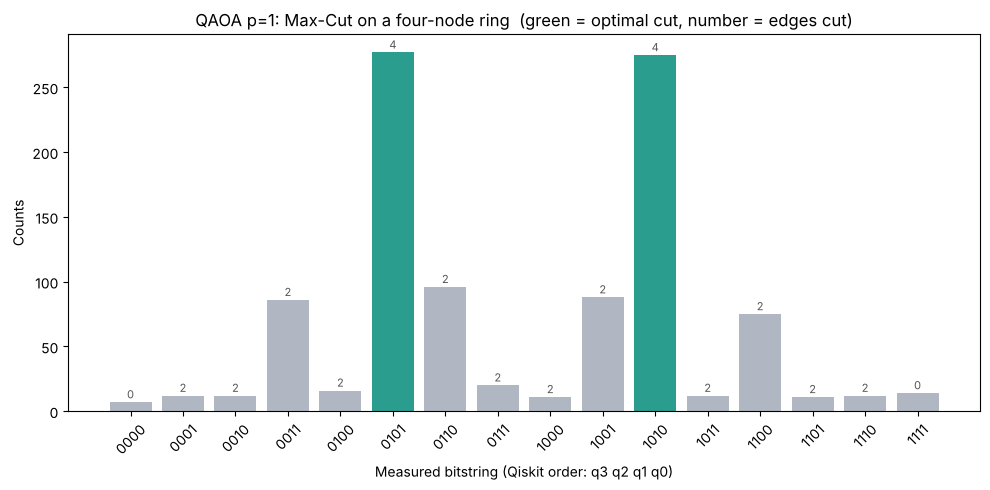

In [7]:
colors = ["#2a9d8f" if cut_value(s) == max_cut else "#b0b7c3" for s in labels]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, values, color=colors)
for bar, s in zip(bars, labels):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3,
            cut_value(s), ha="center", fontsize=8, color="#555")
ax.set_xlabel("Measured bitstring (Qiskit order: q3 q2 q1 q0)")
ax.set_ylabel("Counts")
ax.set_title(f"QAOA p={p}: Max-Cut on a four-node ring  "
             f"(green = optimal cut, number = edges cut)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("qaoa_hist.png", dpi=110)
plt.show()

## Takeaway
At **p = 1** the best possible expected cut is 3.0 out of 4 (a 75% approximation ratio), and about 54% of shots return an optimal cut. Set `p = 2` in section 1 and rerun to reach 100%.